# Random forest for $Y^{\text{time}}$

**Purpose:** the same data as `logistic.ipynb` (outcome, snapshots, test, covariates and their classes from `covariates.ipynb`), fitted with a random forest, and compared with the logistic regression.

- **Input:** `CLEAN_DATA_PATH` (clean merchant-day data), `COVARIATES_PATH` (static classes from `covariates.ipynb`)
- **Output:** `TARGET_LIST_PATH` (final ranked target list from the equal-weight combination of the logistic regression and the forest), `RF_LIST_PATH` (forest-only list)

**Steps**
1. Setup: $H$, $L$, snapshots (chosen in `logistic.ipynb`).
2. Build the samples.
3. Choose the forest settings by time-series cross-validation.
4. Evaluate on the test snapshot, against the logistic regression of `logistic.ipynb`.
5. Score merchants at the end of the data and build the target list.

**Outcome:** for merchant $i$ with first payment $F_i$ and first Subscriptions payment $A_i$ ($A_i = \infty$ if never),

$$Y^{\text{time}}_i = \mathbf{1}\{t_0 \le A_i < t_0 + H\}, \qquad i \in \mathcal{R}(t_0) = \{i : F_i \le t_0 - L, \; A_i \ge t_0, \; \text{payment in } [t_0 - W, t_0)\}.$$

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_rows", 100)

CLEAN_DATA_PATH = Path("output/merchant_day.pkl")
COVARIATES_PATH = Path("output/merchant_covariates.pkl")
TARGET_LIST_PATH = Path("output/target_list_combined.csv")      # final list: equal-weight combination
RF_LIST_PATH = Path("output/target_list_time_rf.csv")            # forest-only list
FIGURE_DIR = Path("output")                                      # figures used in the report

W = 90           # covariate window: days before t0
TOP_K = 100      # list size
N_TREES = 300
SEED = 0

In [2]:
df = pd.read_pickle(CLEAN_DATA_PATH)
covariates = pd.read_pickle(COVARIATES_PATH)
static = covariates[["industry", "country", "business_size"]]
START, END = df["date"].min(), df["date"].max()

first_seen = df.groupby("merchant")["date"].min()
first_subscription = df.loc[df["subscription_volume"] > 0].groupby("merchant")["date"].min()
# Tenure clock: first charge date, or first day seen if that is earlier or missing
first_charge = covariates["first_charge_date"].combine(first_seen.reindex(covariates.index), lambda a, b: b if pd.isna(a) else min(a, b))
print(f"data: {START.date()} to {END.date()}, {(END - START).days + 1} days in total")

data: 2041-05-01 to 2042-06-22, 418 days in total


## 1. Setup

Same values as `logistic.ipynb` (see its section 1 for the choice).

In [3]:
H = 90
L = 30
TEST_T0 = END + pd.Timedelta(days=1) - pd.Timedelta(days=H)  # latest test snapshot: outcome window ends on the last day of data

# Monthly rolling training snapshots: enough history before t0, outcome window ends before TEST_T0
TRAIN_SNAPSHOTS = [
    t0 for t0 in pd.date_range(START, END, freq="MS")
    if (t0 - START).days >= max(L, W) and t0 + pd.Timedelta(days=H) <= TEST_T0
]
assert TRAIN_SNAPSHOTS, "no training snapshot fits before the test snapshot"
assert TEST_T0 + pd.Timedelta(days=H) <= END + pd.Timedelta(days=1), "test outcome window goes past the data"

print("training snapshots:", [t0.date().isoformat() for t0 in TRAIN_SNAPSHOTS])
print(f"test snapshot: {TEST_T0.date()}, {(TEST_T0 - START).days} days before it, {(END - TEST_T0).days + 1} days from it to the end of data")

training snapshots: ['2041-08-01', '2041-09-01', '2041-10-01', '2041-11-01', '2041-12-01']
test snapshot: 2042-03-25, 328 days before it, 90 days from it to the end of data


## 2. Samples

Covariates use only payments in $[t_0 - W, t_0)$; merchants in the risk set have no Subscriptions volume before $t_0$, so `total_volume` is non-Subscriptions volume.

- `log_volume`, `log_checkout_volume`, `log_payment_link_volume`: $\log(1 + \text{volume in the window})$
- `active_rate`: days with volume in the window ÷ $\min(W, \text{days observed})$
- `recency`: days from the last payment to $t_0 - 1$
- `log_tenure`: $\log(t_0 - \text{first charge date})$ in days; tenure is right-skewed, and adoption falls roughly linearly in log tenure
- `industry` [Others], `country` [US], `business_size` [small]: classes from `covariates.ipynb`

In [4]:
REFERENCE = {"industry": "Others", "country": "US", "business_size": "small"}
DISCRETE = list(REFERENCE)
CONTINUOUS = ["log_volume", "log_checkout_volume", "log_payment_link_volume", "active_rate", "recency", "log_tenure"]


def build_sample(t0, with_outcome=True):
    window = df[(df["date"] >= t0 - pd.Timedelta(days=W)) & (df["date"] < t0)]
    g = window.groupby("merchant")
    start = first_subscription.reindex(g.size().index)
    observed = (t0 - first_seen.reindex(g.size().index)).dt.days
    risk_set = (observed >= L) & ~(start < t0)

    s = static.loc[risk_set[risk_set].index].copy()
    g = window[window["merchant"].isin(s.index)].groupby("merchant")
    s["log_volume"] = np.log1p(g["total_volume"].sum())
    s["log_checkout_volume"] = np.log1p(g["checkout_volume"].sum())
    s["log_payment_link_volume"] = np.log1p(g["payment_link_volume"].sum())
    s["active_rate"] = g.size() / np.minimum(W, observed.reindex(s.index))
    s["recency"] = (t0 - pd.Timedelta(days=1) - g["date"].max()).dt.days
    s["log_tenure"] = np.log((t0 - first_charge.reindex(s.index)).dt.days)  # tenure >= L days, so no +1 needed
    if with_outcome:
        s["y"] = ((start >= t0) & (start < t0 + pd.Timedelta(days=H))).reindex(s.index).astype(int)
    return s


def design_matrix(s, columns=None):
    dummies = [pd.get_dummies(s[col], prefix=col, dtype=float).drop(columns=f"{col}_{ref}", errors="ignore")
               for col, ref in REFERENCE.items()]
    X = pd.concat([s[CONTINUOUS]] + dummies, axis=1)
    return X if columns is None else X.reindex(columns=columns, fill_value=0.0)


train = pd.concat([build_sample(t0).assign(snapshot=t0.date()) for t0 in TRAIN_SNAPSHOTS])
test = build_sample(TEST_T0).assign(snapshot=TEST_T0.date())

summary = pd.concat([train, test.assign(snapshot=f"{TEST_T0.date()} (test)")]).groupby("snapshot", sort=False)["y"]
summary = pd.DataFrame({"merchants": summary.size(), "Y_time = 1": summary.sum(), "rate (%)": (summary.mean() * 100).round(2)})
summary.loc["train total"] = [len(train), train["y"].sum(), round(train["y"].mean() * 100, 2)]
print(f"training rows: {len(train):,} from {train.index.nunique():,} merchants")
summary

training rows: 51,310 from 13,885 merchants


,merchants,Y_time = 1,rate (%)
snapshot,,,
2041-08-01,9822.0,110.0,1.12
2041-09-01,10057.0,108.0,1.07
2041-10-01,10192.0,101.0,0.99
2041-11-01,10475.0,101.0,0.96
2041-12-01,10764.0,100.0,0.93
2042-03-25 (test),11005.0,110.0,1.00
train total,51310.0,520.0,1.01


## 3. Choose the forest settings by cross-validation

- `min_samples_leaf`: smallest number of rows in a leaf; larger means smoother scores and less overfitting to the few positives.
- `max_features`: share of covariates tried at each split.
- **Time-series CV**: each fold validates on one training snapshot and fits on the earlier snapshots whose outcome window ($H$ days) ends before it. With $H$ = 90 and monthly snapshots this leaves 2 folds.
- Metric: AUC. Chosen: the settings with the largest mean CV AUC.

In [5]:
LEAF_GRID = [10, 25, 50, 100, 200, 400]
FEATURES_GRID = ["sqrt", 0.3]

X_train = design_matrix(train)
y_train = train["y"].to_numpy()

snap = pd.to_datetime(train["snapshot"])
folds = []
for val_t0 in TRAIN_SNAPSHOTS:
    fit_idx = np.where(snap + pd.Timedelta(days=H) <= val_t0)[0]
    if len(fit_idx):
        folds.append((fit_idx, np.where(snap == val_t0)[0]))
        print(f"fold: fit on {[d.isoformat() for d in sorted(set(train['snapshot'].iloc[fit_idx]))]}, validate on {val_t0.date()}")


def forest(min_samples_leaf, max_features):
    return RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=min_samples_leaf,
                                  max_features=max_features, n_jobs=-1, random_state=SEED)


cv_auc = []
for leaf in LEAF_GRID:
    for features in FEATURES_GRID:
        aucs = []
        for fit_idx, val_idx in folds:
            m = forest(leaf, features).fit(X_train.iloc[fit_idx], y_train[fit_idx])
            aucs.append(roc_auc_score(y_train[val_idx], m.predict_proba(X_train.iloc[val_idx])[:, 1]))
        cv_auc.append({"min_samples_leaf": leaf, "max_features": str(features), "CV AUC mean": np.mean(aucs), "CV AUC sd": np.std(aucs)})
cv_auc = pd.DataFrame(cv_auc)
best = cv_auc.loc[cv_auc["CV AUC mean"].idxmax()]
BEST_LEAF = int(best["min_samples_leaf"])
BEST_FEATURES = "sqrt" if best["max_features"] == "sqrt" else float(best["max_features"])
print(f"chosen: min_samples_leaf = {BEST_LEAF}, max_features = {BEST_FEATURES}")
cv_auc.pivot(index="min_samples_leaf", columns="max_features", values=["CV AUC mean", "CV AUC sd"]).round(4)

fold: fit on ['2041-08-01'], validate on 2041-11-01
fold: fit on ['2041-08-01', '2041-09-01'], validate on 2041-12-01


chosen: min_samples_leaf = 100, max_features = sqrt


CV AUC mean         CV AUC sd        
max_features             0.3    sqrt       0.3    sqrt
min_samples_leaf                                      
10                    0.6962  0.7077    0.0297  0.0296
25                    0.7133  0.7227    0.0216  0.0222
50                    0.7229  0.7267    0.0224  0.0216
100                   0.7248  0.7332    0.0240  0.0181
200                   0.7210  0.7328    0.0180  0.0190
400                   0.7138  0.7205    0.0140  0.0173

## 4. Evaluate on the test snapshot

Forest with the chosen settings vs the logistic regression of `logistic.ipynb` (same covariates, no penalty), both fitted on all training rows, and their equal-weight combination: the average of the two models' rank percentiles. Lift = adoption rate among the selected merchants ÷ adoption rate in the whole test sample. PR-AUC (average precision) summarizes precision over all recall levels; a random ranking scores the base rate, about 0.01.

In [6]:
model = forest(BEST_LEAF, BEST_FEATURES).fit(X_train, y_train)
logit_main = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=False)  # same fit as logistic.ipynb

X_test = design_matrix(test, X_train.columns)
base_rate = test["y"].mean()
scores = {
    "random forest": pd.Series(model.predict_proba(X_test)[:, 1], index=test.index),
    "logistic (main model)": pd.Series(np.asarray(logit_main.predict(sm.add_constant(X_test, has_constant="add"))), index=test.index),
}
# Equal-weight combination: average of the two models' rank percentiles
scores["combined (w = 0.5)"] = 0.5 * scores["logistic (main model)"].rank(pct=True) + 0.5 * scores["random forest"].rank(pct=True)
rows = {}
for name, score in scores.items():
    ranked = test["y"].loc[score.sort_values(ascending=False, kind="stable").index]
    rows[name] = {
        "test AUC": round(roc_auc_score(test["y"], score), 3),
        "test PR-AUC": round(average_precision_score(test["y"], score), 3),
        "lift top 1%": round(ranked.head(len(test) // 100).mean() / base_rate, 2),
        f"lift top {TOP_K}": round(ranked.head(TOP_K).mean() / base_rate, 2),
        "positives in top 1%": int(ranked.head(len(test) // 100).sum()),
    }
pd.DataFrame(rows).T

,test AUC,test PR-AUC,lift top 1%,lift top 100,positives in top 1%
random forest,0.718,0.033,6.37,7.0,7.0
logistic (main model),0.727,0.032,6.37,7.0,7.0
combined (w = 0.5),0.732,0.034,8.19,9.0,9.0


### Lift curve

Adoption rate among the top $k$% of the test snapshot ÷ base rate, for both models. Shows whether the forest wins only at the very top or over the whole ranking.

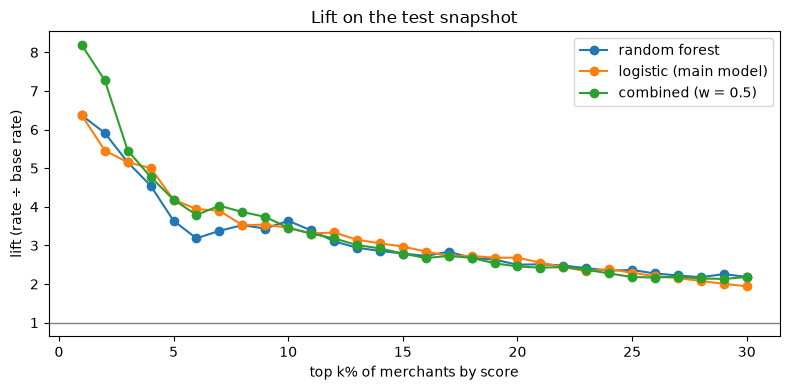

In [7]:
shares = np.arange(1, 31)  # top 1% ... 30%
fig, ax = plt.subplots(figsize=(8, 4))
for name, score in scores.items():
    ranked = test["y"].loc[score.sort_values(ascending=False, kind="stable").index].to_numpy()
    ax.plot(shares, [ranked[: len(ranked) * k // 100].mean() / base_rate for k in shares], marker="o", label=name)
ax.axhline(1, color="gray", linewidth=1)
ax.set_xlabel("top k% of merchants by score")
ax.set_ylabel("lift (rate ÷ base rate)")
ax.set_title("Lift on the test snapshot")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lift_logistic_rf.png", dpi=150)

### Lift at the very top of the ranking

Lift for small list sizes, with the number of adopters found in parentheses (110 adopters among 11,005 merchants in the test snapshot). Below 1% each list holds only a few dozen merchants, so one more adopter changes the lift a lot (by about 9 at the top 0.1%, about 1.8 at the top 0.5%).

In [8]:
TOP_SHARES = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 2.0, 5.0]  # top k% of merchants
n_test = len(test)
sizes_top = {p: max(1, round(n_test * p / 100)) for p in TOP_SHARES}
top_lift = pd.DataFrame(index=pd.Index([f"{p}%" for p in TOP_SHARES], name="top k%"))
top_lift["merchants"] = list(sizes_top.values())
for name, score in scores.items():
    ranked = test["y"].loc[score.sort_values(ascending=False, kind="stable").index].to_numpy()
    top_lift[name] = [f"{ranked[:k].mean() / base_rate:.1f} ({int(ranked[:k].sum())})" for k in sizes_top.values()]
top_lift

,merchants,random forest,logistic (main model),combined (w = 0.5)
top k%,,,,
0.1%,11,9.1 (1),0.0 (0),9.1 (1)
0.2%,22,13.6 (3),4.5 (1),9.1 (2)
0.3%,33,12.1 (4),6.1 (2),9.1 (3)
0.5%,55,7.3 (4),9.1 (5),7.3 (4)
0.7%,77,9.1 (7),9.1 (7),7.8 (6)
1.0%,110,6.4 (7),6.4 (7),8.2 (9)
2.0%,220,5.9 (13),5.5 (12),7.3 (16)
5.0%,550,3.6 (20),4.2 (23),4.2 (23)


### Precision-recall curve

Precision (share of adopters among the selected merchants) against recall (share of all adopters found), as the list grows from the top of the ranking. With adopters this rare, it shows the trade-off at the top of the list more clearly than the ROC curve; the dashed line is a random ranking (the base rate).

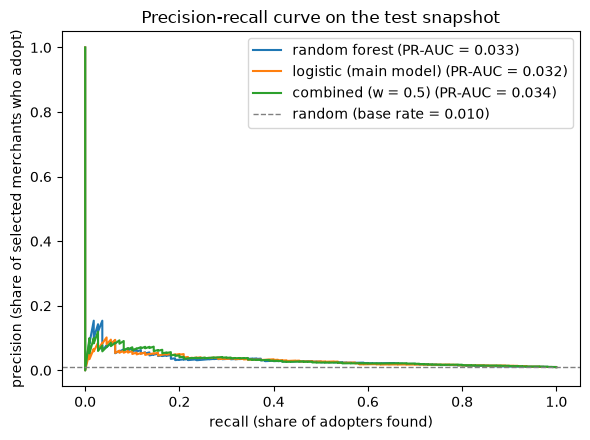

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, score in scores.items():
    precision, recall, _ = precision_recall_curve(test["y"], score)
    ax.plot(recall, precision, label=f"{name} (PR-AUC = {average_precision_score(test['y'], score):.3f})")
ax.axhline(base_rate, color="gray", linestyle="--", linewidth=1, label=f"random (base rate = {base_rate:.3f})")
ax.set_xlabel("recall (share of adopters found)")
ax.set_ylabel("precision (share of selected merchants who adopt)")
ax.set_title("Precision-recall curve on the test snapshot")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "pr_logistic_rf.png", dpi=150)

## 5. Target lists

Score the merchants at risk on the day after the last day of data with both models and keep the `TOP_K` highest.

- **Final list** (`TARGET_LIST_PATH`): the equal-weight combination, i.e. the average of the two models' rank percentiles, as evaluated in section 4. It also keeps each model's own score: `logistic_probability` (estimated probability of adopting within 90 days) and `rf_score` (forest score, for ranking only).
- **Forest-only list** (`RF_LIST_PATH`).

Medium/large → sales, small → marketing.

In [10]:
t_score = END + pd.Timedelta(days=1)
pool = build_sample(t_score, with_outcome=False)
X_pool = design_matrix(pool, X_train.columns)
pool["rf_score"] = model.predict_proba(X_pool)[:, 1]
pool["logistic_probability"] = np.asarray(logit_main.predict(sm.add_constant(X_pool, has_constant="add")))
pool["score"] = 0.5 * pool["logistic_probability"].rank(pct=True) + 0.5 * pool["rf_score"].rank(pct=True)


def top_list(score_col, extra=()):
    return (
        pool.sort_values(score_col, ascending=False, kind="stable").head(TOP_K)
        .assign(rank=lambda t: np.arange(1, len(t) + 1),
                channel=lambda t: np.where(t["business_size"] == "small", "marketing", "sales"))
        [["rank", score_col, *extra, "channel", "industry", "country", "business_size"] + CONTINUOUS]
    )


targets = top_list("score", extra=("logistic_probability", "rf_score"))
targets.to_csv(TARGET_LIST_PATH)
RF_LIST_PATH.parent.mkdir(parents=True, exist_ok=True)
top_list("rf_score").rename(columns={"rf_score": "score"}).to_csv(RF_LIST_PATH)
print(f"pool: {len(pool):,} merchants; final list: top {len(targets)} by the combined score")
targets.head(10)

pool: 11,402 merchants; final list: top 100 by the combined score


,rank,score,logistic_probability,rf_score,channel,industry,country,business_size,log_volume,log_checkout_volume,log_payment_link_volume,active_rate,recency,log_tenure
merchant,,,,,,,,,,,,,,
740224c1,1,0.999912,0.175258,0.056505,marketing,Business services,US,small,10.457401,0.0,9.575053,0.078125,7,4.158883
67cdfdbd,2,0.999737,0.143443,0.054952,marketing,Business services,Rest of world,small,8.323807,0.0,8.323807,0.258065,1,3.433987
84627c91,3,0.999737,0.175916,0.054168,marketing,Personal services,Rest of world,small,9.927112,0.0,9.813508,0.159091,1,3.784190
2bd7dae3,4,0.999693,0.156469,0.054488,marketing,Personal services,US,small,9.680031,0.0,9.680031,0.071429,5,4.025352
a11c5d49,5,0.999561,0.142056,0.054623,marketing,Business services,US,small,10.596972,0.0,10.021870,0.100000,7,5.351858
92e17b8d,6,0.999298,0.135733,0.053535,marketing,Business services,US,small,7.958926,0.0,7.601402,0.133333,0,3.401197
a0dd9f26,7,0.999035,0.121450,0.053274,marketing,Business services,US,small,8.460834,0.0,8.460834,0.068493,14,4.290459
fa0c65ad,8,0.998772,0.127418,0.050995,marketing,Business services,US,small,7.844241,0.0,7.844241,0.031250,1,4.158883
b84d83d2,9,0.998553,0.110843,0.051922,marketing,Business services,US,small,8.585920,0.0,8.585920,0.022222,6,5.332719


### Overlap of the two target lists

Share of the logistic regression's (same fit as `logistic.ipynb`) top $K$ merchants that are also in the random forest's top $K$, on the day after the data ends, for list sizes $K$ from 10 to 1,000.

overlap at K = 100: 60%; at K = 500: 62%; at K = 1000: 67%


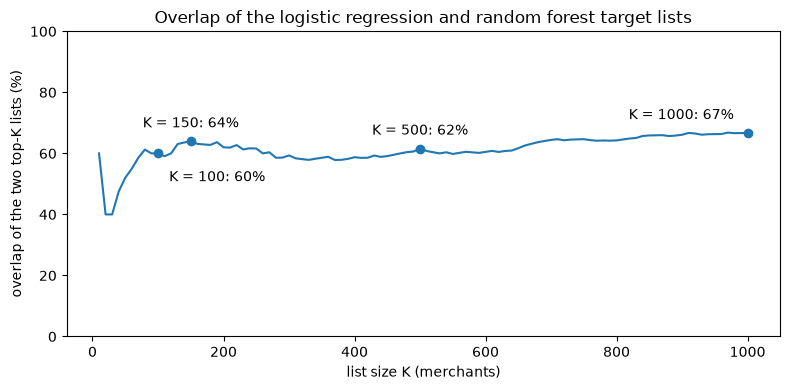

In [11]:
rank_rf = pool["rf_score"].sort_values(ascending=False).index
rank_logit = pool["logistic_probability"].sort_values(ascending=False).index
sizes = np.arange(10, 1001, 10)
overlap = np.array([len(set(rank_rf[:k]) & set(rank_logit[:k])) / k for k in sizes])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, overlap * 100)
MARKS = {100: (8, -20), 150: (0, 10), 500: (0, 10), 1000: (-10, 10)}  # list size: label offset in points
for k, offset in MARKS.items():
    v = overlap[sizes == k][0] * 100
    ax.scatter([k], [v], zorder=3, color="C0")
    ax.annotate(f"K = {k}: {v:.0f}%", (k, v), textcoords="offset points", xytext=offset, ha={100: "left", 1000: "right"}.get(k, "center"))
k100 = overlap[sizes == TOP_K][0] * 100
ax.set_ylim(0, 100)
ax.set_xlabel("list size K (merchants)")
ax.set_ylabel("overlap of the two top-K lists (%)")
ax.set_title("Overlap of the logistic regression and random forest target lists")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "overlap_logistic_rf.png", dpi=150)
print(f"overlap at K = {TOP_K}: {k100:.0f}%; at K = 500: {overlap[sizes == 500][0]:.0%}; at K = 1000: {overlap[-1]:.0%}")